# Hof_malanga_comparison — DiscEvolution vs Malanga et al. (2026)

**Goal.** Test whether the weak correlation between disc mass $M$ and stellar accretion rate $\dot M_*$ that Malanga et al. (2026) find for MHD-wind-driven discs (their Fig. 4) also appears in DiscEvolution's hybrid viscous + wind model. The population here is drawn from Malanga's inferred MHD-wind distributions (their Eq. 7 and Table 2, MHD-winds column) at $M_* = 1\,M_\odot$, with:
- fixed viscous $\alpha_{SS} = 10^{-4}$;
- $\psi = \alpha_{\rm tot}/\alpha_{SS} - 1$;
- $e_{\rm rad}$ mapped from Malanga's $f_M$ (their Eq. 6), via the steady-state wind relation and the code's $\lambda(e_{\rm rad},\psi)$ (Balogh et al. 2026, Eq. 16).

**Pipeline** (all in `example/StartHere/`):
- `sample_malanga_Hof.py` → `config/malanga/malanga_draws_Hof_N500_seed1.csv` (one row per disc: parameters + sampled age $t_{\rm age}$)
- `run_popsynth_malanga_Hof.sh` + `config/popsynth/DiscConfig_Hof_malanga.json` (grid 0.1–250 AU, 500 cells, 34 snapshots to 3 Myr)
- outputs: one `hof_malanga_w0_<id>_*.h5` per disc, next to a copy of the population CSV

**Units** (see `CLAUDE.md`):

| Quantity | Units |
|---|---|
| HDF5 `t` | yr |
| `time_snap` | Myr |
| `disk_Mass` | g (÷ `Msun`) |
| `disk_Mdot_star` | M$_\odot$/yr |
| `T` | K |
| `R` | AU |

**Notebook sections**
1. Run check (this first cell): completion, runtime, file size, and the gravitational-instability (GI) flag of the initial disc, i.e. Toomre $Q < 1.5$ (Toomre 1964; Balogh et al. 2026, Eq. 48), with the radius where the unstable region begins.
   - 1b: table of the GI-flagged discs, with their parameters and initial conditions only.
2. Parameter comparisons: achieved $f_M$ (instantaneous and cumulative) vs target, $M/\dot M$ vs analytic, disc spreading.
3. Malanga et al. (2026) Fig. 4(b): $\dot M$ vs $M$ at each disc's age, with the viscous isochrone $M/\dot M = 2\,t_{\rm Lupus}$ ($t_{\rm Lupus}$ = 1.6 Myr), GI-flagged discs as triangles.


In [3]:
# =====================================================================================
# 1. Run check: one row per disc in DATA_DIR (from check_malanga_pilot_Hof.py, reduced)
# =====================================================================================
# Columns:
#   id          disc id (row of the population CSV; run_name = hof_malanga_w0_<id>)
#   R0_au       characteristic radius R0 [AU]                       (population CSV)
#   M0_Msun     initial disc mass M0 [Msun]                         (population CSV)
#   complete    HDF5 attr complete = True AND last snapshot time_snap[-1] reached T_END_MYR (Myr)
#   runtime_h   wall-clock run_end - run_start [h] (HDF5 attrs; includes set-up)
#   size_MB     file size [MB]
#   GI_flag     gravitational instability of the INITIAL disc: Toomre (1964) Q = c_s Omega / (pi G Sigma)
#               (Balogh et al. 2026, Eq. 48) evaluated on every grid cell; flagged if Q < 1.5 anywhere
#               (see disc_setup_Hof.gi_check_toomre)
#   GI_R_au     radius [AU] where the disc ENTERS the unstable region going outward (innermost crossing
#               of Q = 1.5); NaN if not flagged. (The outer edge is in HDF5 attr GI_R_out_au.)
#   GI_source   'attr' = read from the HDF5 attrs written by run_model_Hof.py; 'recomputed' = file
#               written before those attrs existed (e.g. pilot1), recomputed here with the SAME function
#               from the t = 0 snapshot: gas surface density Sigma_G[0] and temperature T[0].
# Nothing is written to disk. Parameter comparisons come in later cells.
import os, sys, glob, re
from datetime import datetime
import numpy as np
import pandas as pd
import h5py

# ---- where things are -------------------------------------------------------------
DATA_DIR = "/home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/full"
T_END_MYR = 3.0          # Myr, last snapshot of DiscConfig_Hof_malanga.json
T_END_RTOL = 1e-3        # relative tolerance for "reached the end" (dimensionless)

STARTHERE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))     # notebook lives in StartHere/notebooks/
if STARTHERE_DIR not in sys.path:
    sys.path.insert(0, STARTHERE_DIR)
from disc_setup_Hof import gi_check_toomre                            # Toomre Q GI check (Balogh+26 Eq. 48)
from DiscEvolution.constants import AU, Omega0, GasConst              # cm, s^-1, erg/mol/K

MU_EOS = 2.4             # mean molecular weight IrradiatedEOS uses (its default; make_eos does not pass mu)


def cs_omega_code_units(R_au, T_K, M_star):
    """Sound speed and Keplerian Omega in DiscEvolution code units (G = AU = Msun = 1), exactly as
    IrradiatedEOS / SimpleStar compute them:
        c_s = cs0 sqrt(T),  cs0 = (Omega0^-1 / AU) sqrt(GasConst / mu)     [AU per code-time unit]
        Omega_K = sqrt(M* / R^3)                                             [per code-time unit]
    R in AU, T in K, M* in Msun."""
    cs = (1 / Omega0 / AU) * np.sqrt(GasConst / MU_EOS) * np.sqrt(T_K)
    return cs, np.sqrt(M_star / R_au ** 3)


def run_row(path, draws):
    """Run-check row for one .h5 file (see column list above)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    row = {"id": disc_id, "R0_au": d.R0_au, "M0_Msun": d.M0_Msun}
    with h5py.File(path, "r") as h:
        a = h.attrs
        t_last = float(h["time_snap"][-1]) if ("time_snap" in h and len(h["time_snap"])) else np.nan   # Myr
        row["complete"] = bool(a.get("complete", False)) and bool(t_last >= T_END_MYR * (1 - T_END_RTOL))
        row["runtime_h"] = np.nan
        if "run_start" in a and "run_end" in a:
            row["runtime_h"] = (datetime.fromisoformat(str(a["run_end"]))
                                - datetime.fromisoformat(str(a["run_start"]))).total_seconds() / 3600
        row["size_MB"] = os.path.getsize(path) / 1e6
        if "GI_flag" in a and "GI_R_in_au" in a:                     # written by run_model_Hof.py
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = bool(a["GI_flag"]), float(a["GI_R_in_au"]), "attr"
        elif "Sigma_G" in h and len(h["Sigma_G"]) and np.isclose(h["time_snap"][0], 0.0):
            # recompute from the t = 0 snapshot (same criterion and function as the attrs)
            R = h["R"][:]                                                            # AU
            cs, Om = cs_omega_code_units(R, h["T"][0], d.Mstar_Msun)
            gi = gi_check_toomre(R, h["Sigma_G"][0], cs, Om)                         # Sigma_G[0] in g/cm^2
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = gi["GI_flag"], gi["GI_R_in_au"], "recomputed"
        else:
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = np.nan, np.nan, "unavailable"
    return row


def show_table(df, formats=None, default="{:.3g}"):
    """Return a display copy of `df` with float columns formatted as strings (default 3 significant
    figures; per-column overrides in `formats`) and NaN shown as '—'. Plain pandas: unlike
    DataFrame.style it does not need the optional jinja2 package (missing in the Nibi venv)."""
    formats = formats or {}
    out = df.copy()
    for col in out.columns:
        if pd.api.types.is_float_dtype(out[col]):
            fmt = formats.get(col, default)
            out[col] = out[col].map(lambda v: "—" if pd.isna(v) else fmt.format(v))
    return out

csvs = glob.glob(os.path.join(DATA_DIR, "malanga_draws_Hof_*.csv"))
assert len(csvs) == 1, f"expected exactly one malanga_draws_Hof_*.csv in {DATA_DIR}, found {csvs}"
draws = pd.read_csv(csvs[0]).set_index("id")
files = sorted(glob.glob(os.path.join(DATA_DIR, "hof_malanga_w0_*.h5")))
assert files, f"no hof_malanga_w0_*.h5 files in {DATA_DIR}"

run_check = pd.DataFrame([run_row(f, draws) for f in files]).sort_values("id").reset_index(drop=True)
print(f"{len(run_check)} discs in {DATA_DIR}  |  complete: {int(run_check.complete.sum())}  |  "
      f"GI-flagged (Q < 1.5): {int(run_check.GI_flag.fillna(False).sum())}  |  runtime median "
      f"{run_check.runtime_h.median():.2f} h, max {run_check.runtime_h.max():.2f} h  |  "
      f"total size {run_check.size_MB.sum():.0f} MB")
show_table(run_check, {"runtime_h": "{:.2f}", "size_MB": "{:.1f}"})


500 discs in /home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/full  |  complete: 500  |  GI-flagged (Q < 1.5): 32  |  runtime median 0.15 h, max 1.27 h  |  total size 2716 MB


,id,R0_au,M0_Msun,complete,runtime_h,size_MB,GI_flag,GI_R_au,GI_source
0,0,52,0.0766,True,0.10,3.9,False,—,recomputed
1,1,30.9,0.128,True,0.13,4.1,False,—,recomputed
2,2,25.1,0.0779,True,0.15,4.3,False,—,recomputed
3,3,13.3,0.0283,True,0.12,3.9,False,—,recomputed
4,4,11.2,0.0578,True,0.29,5.2,False,—,recomputed
...,...,...,...,...,...,...,...,...,...
495,495,14.6,0.0825,True,0.12,3.9,False,—,attr
496,496,24.9,0.136,True,0.15,4.4,False,—,attr
497,497,15.2,0.0632,True,0.12,3.9,False,—,attr
498,498,3.74,0.0328,True,0.67,7.6,False,—,attr


In [4]:
# =====================================================================================
# 1b. GI-flagged discs: parameters and initial conditions only (needs cell 1)
# =====================================================================================
# One row per disc with GI_flag = True (Toomre Q < 1.5 somewhere in the INITIAL disc; Balogh et al.
# 2026 Eq. 48), sorted from most to least unstable (Q_min ascending). Only INPUTS and the INITIAL state
# are shown -- nothing measured during the evolution and no analytic estimates (f_M_grid_expected,
# t_acc0_Myr, Mdot0_est are deliberately left out). Columns:
#   sampled parameters (population CSV; Malanga et al. 2026 Eq. 7 at M* = 1 Msun):
#     M0_Msun [Msun], R0_au [AU], alpha_tot [-], t_age_Myr [Myr] (age the disc is analysed at)
#   wind mapping (population CSV): alpha_SS [-] (fixed), psi_DW = alpha_tot/alpha_SS - 1 [-],
#     f_M [-] (Malanga's input value), xi [-] (Malanga Eq. 6), e_rad [-], lambda_DW [-] (code's lever arm)
#   M0_over_Mstar [-]  initial disc-to-star mass ratio
#   initial disc as built by the code (HDF5 attrs, or recomputed from the t = 0 snapshot as in cell 1):
#     Mdot0_code [Msun/yr]  inner accretion rate at R_c[0] ~ 0.11 AU (attr calib_Mdot)
#     Q_min [-], R_Qmin_au [AU]  minimum Toomre Q and where it occurs
#     GI_R_in_au, GI_R_out_au [AU]  where the disc enters / leaves the unstable region (Q < 1.5);
#                                   R_in = 0.11 AU means the innermost cell is already unstable
#     GI_n_regions [-]  number of separate unstable annuli
#     GI_source  'attr' or 'recomputed' (as in cell 1)


def gi_details(path, d):
    """Full GI result for one file: from HDF5 attrs if present, else recomputed from the t = 0
    snapshot (Sigma_G[0], T[0]) with the same function the model uses (see cell 1)."""
    with h5py.File(path, "r") as h:
        a = h.attrs
        out = {"Mdot0_code": float(a["calib_Mdot"]) if "calib_Mdot" in a else np.nan}     # Msun / yr
        if "GI_flag" in a and "GI_R_in_au" in a:
            out.update(Q_min=float(a["Q_toomre_min"]), R_Qmin_au=float(a["Q_toomre_R_au"]),
                       GI_R_in_au=float(a["GI_R_in_au"]), GI_R_out_au=float(a["GI_R_out_au"]),
                       GI_n_regions=int(a["GI_n_regions"]), GI_source="attr")
        else:
            R = h["R"][:]                                                             # AU
            cs, Om = cs_omega_code_units(R, h["T"][0], d.Mstar_Msun)
            g = gi_check_toomre(R, h["Sigma_G"][0], cs, Om)
            out.update(Q_min=g["Q_min"], R_Qmin_au=g["R_Qmin_au"], GI_R_in_au=g["GI_R_in_au"],
                       GI_R_out_au=g["GI_R_out_au"], GI_n_regions=g["GI_n_regions"], GI_source="recomputed")
    return out


gi_ids = set(run_check.loc[run_check.GI_flag.fillna(False).astype(bool), "id"])
gi_rows = []
for f in files:
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(f)).group(1))
    if disc_id not in gi_ids:
        continue
    d = draws.loc[disc_id]
    gi_rows.append({"id": disc_id, "M0_Msun": d.M0_Msun, "R0_au": d.R0_au, "alpha_tot": d.alpha_tot,
                    "t_age_Myr": d.t_age_Myr, "alpha_SS": d.alpha_SS, "psi_DW": d.psi_DW, "f_M": d.f_M,
                    "xi": d.xi, "e_rad": d.e_rad, "lambda_DW": d.lambda_DW,
                    "M0_over_Mstar": d.M0_Msun / d.Mstar_Msun, **gi_details(f, d)})

if not gi_rows:
    print(f"No GI-flagged discs among the {len(run_check)} discs in {DATA_DIR}.")
    gi_table = pd.DataFrame()
else:
    gi_table = pd.DataFrame(gi_rows).sort_values("Q_min").reset_index(drop=True)
    print(f"{len(gi_table)} of {len(run_check)} discs are GI-flagged (Toomre Q < 1.5 in the initial disc).")
    # context: how the flagged discs' sampled parameters compare with all discs in DATA_DIR
    allp = draws.loc[run_check.id]
    for col, lab, unit in [("M0_Msun", "M0", "Msun"), ("R0_au", "R0", "AU"), ("alpha_tot", "alpha_tot", "")]:
        print(f"  median {lab:9s}: flagged {gi_table[col].median():.3g} {unit:4s}  |  all discs {allp[col].median():.3g} {unit}")
show_table(gi_table, {"alpha_SS": "{:.1e}", "e_rad": "{:.6g}", "Mdot0_code": "{:.2e}"}) if len(gi_table) else None


32 of 500 discs are GI-flagged (Toomre Q < 1.5 in the initial disc).
  median M0       : flagged 0.322 Msun  |  all discs 0.0563 Msun
  median R0       : flagged 17.3 AU    |  all discs 17.4 AU
  median alpha_tot: flagged 0.00418       |  all discs 0.00435 


,id,M0_Msun,R0_au,alpha_tot,t_age_Myr,alpha_SS,psi_DW,f_M,xi,e_rad,lambda_DW,M0_over_Mstar,Mdot0_code,Q_min,R_Qmin_au,GI_R_in_au,GI_R_out_au,GI_n_regions,GI_source
0,215,1.76,15.9,0.00404,1.77,1.0e-04,39.4,0.251,0.0357,0.965899,14.6,1.76,8.38e-06,0.311,34.6,0.961,70.9,1,recomputed
1,391,0.729,23.1,0.00334,1.52,1.0e-04,32.5,0.251,0.0337,0.968132,15.4,0.729,1.98e-06,0.462,30.7,9.47,74.9,1,attr
2,255,0.572,14.4,0.00436,1.73,1.0e-04,42.6,0.251,0.0363,0.96522,14.4,0.572,3.24e-06,0.684,25.4,10.1,44.7,1,attr
3,295,0.559,1.33,0.00546,0.743,1.0e-04,53.6,0.251,0.0591,0.942897,9.29,0.559,4.18e-05,0.691,0.685,0.11,2.61,1,recomputed
4,121,0.585,14.7,0.00557,1.98,1.0e-04,54.7,0.251,0.0362,0.965044,14.6,0.585,4.10e-06,0.691,26.4,10.6,46.2,1,attr
5,352,1.05,5.82,0.00286,1.99,1.0e-04,27.6,0.251,0.0425,0.960122,12.3,1.05,9.71e-06,0.777,6.26,0.359,24.4,1,attr
6,364,0.409,51.9,0.00502,1.72,1.0e-04,49.2,0.251,0.0301,0.971061,17.3,0.409,7.42e-07,0.794,39.9,15.7,110,1,attr
7,489,0.377,22.3,0.0053,1.3,1.0e-04,52,0.251,0.0339,0.967301,15.5,0.377,1.66e-06,0.822,27,12,53,1,attr
8,377,0.374,42.5,0.00584,1.55,1.0e-04,57.4,0.251,0.0309,0.970113,16.9,0.374,9.55e-07,0.838,35.3,16,88.2,1,attr
9,314,0.377,43.6,0.00676,2.06,1.0e-04,66.6,0.251,0.0308,0.970086,17,0.377,1.09e-06,0.838,36.4,16.6,90.4,1,attr


## 2. Parameter comparisons: does each disc do what the mapping intended?
All quantities are evaluated at each disc's own sampled age $t_{\rm age}$ (population CSV, drawn from $N(1.6, 0.3)$ Myr; Malanga et al. 2026, Table 2).

**(a) Wind mass loss, $f_M$.** The $e_{\rm rad}$ mapping targets Malanga's $f_M$ through $\xi = \ln(1+f_M)/\ln(R_0/R_{\rm in})$ (Malanga et al. 2026, Eq. 6), with $R_{\rm in} = 0.03$ AU. Our grid starts at 0.1 AU, so no wind loss happens inside it. The steady-state value the runs can reach is therefore `f_M_grid_expected` $= (R_0/0.1\,{\rm AU})^\xi - 1$. Two measured versions:
- **instantaneous:** $f_{M,\rm inst}(t) = \dot M_{\rm wind}/\dot M_*$, with $\dot M_{\rm wind} = -\,dM/dt - \dot M_*$. It is measured over a $\pm$`DT_WIN_MYR` window around $t_{\rm age}$, which suppresses step-to-step noise. This is the quantity the steady-state mapping predicts.
- **cumulative:** $f_{M,\rm cum}(t) = M_{\rm wind}(t)/M_{\rm acc}(t)$, with $M_{\rm acc} = \int_0^t \dot M_*\,dt'$ and $M_{\rm wind} = M_0 - M(t) - M_{\rm acc}$. It includes the early, non-steady phase.

Caveats:
- $\dot M_*$ is measured at the inner cell, $R_c[0] \approx 0.11$ AU, from the gas velocity. Dust drifting through the inner edge faster than the gas ($d2g = 0.01$) is therefore counted as wind, at the $\lesssim 1\%$ level.
- For discs with $R_0 > 250$ AU, extending beyond the grid, mass leaving through the outer boundary is also counted as wind. These discs are shaded in panel (a).

**(b) Accretion timescale.** $\tau = M/\dot M_*$ at $t_{\rm age}$ is compared with the analytic $\omega = 0$ value $2\,t_{\rm acc,0}(1+f_M)$. That value follows from Malanga Eq. 5 with $\omega = 0$: $M = M_0\,e^{-t/2t_{\rm acc,0}}$ and $\dot M_* = M/[2\,t_{\rm acc,0}(1+f_M)]$ (form to verify against Tabone et al. 2022). Here $t_{\rm acc,0}$ is computed with Malanga's $H/r$ (their Eq. 3).
- **Expected difference:** the code's temperature differs from Malanga's Eq. 3. The inner disc sits at $T_{\max} = 1500$ K, and the region near $R_0$ is colder than Eq. 3 (the Step 3 sampler-test flag, where the initial $\dot M$ was ≈2.2× the analytic estimate).

**(c) Disc spreading.** The half-mass radius $R_{50}(t)$ comes from the $\Sigma_G$ snapshots. Malanga's pure-wind discs do not spread, so $R_{50}$ stays at $R_0\ln 2$. Our hybrid discs keep a small viscous torque, $\alpha_{SS} = 10^{-4}$, about 2% of the total, so they should spread slowly.

**Flags** carried through: `GI_flag` (section 1), and `beyond_grid` ($R_0 >$ the outer grid radius).


In [5]:
# =====================================================================================
# 2. Parameter comparisons (needs cell 1: DATA_DIR, draws, files, run_check)
# =====================================================================================
from DiscEvolution.constants import Msun                              # g
DT_WIN_MYR = 0.05        # Myr, half-width of the window for the instantaneous f_M (dM/dt and mean Mdot)


def interp_profile_at(t_Myr, t_snap, profiles):
    """Linear interpolation of per-snapshot values (time_snap in Myr) to time t_Myr."""
    return np.interp(t_Myr, t_snap, profiles)


def r50(R, Sigma):
    """Half-mass radius [AU] of a surface-density profile on cell centres R [AU] (trapezoid in r)."""
    m = np.concatenate([[0.0], np.cumsum(0.5 * (R[1:] * Sigma[1:] + R[:-1] * Sigma[:-1]) * np.diff(R))])
    return float(np.interp(0.5, m / m[-1], R)) if m[-1] > 0 else np.nan


def compare_row(path, draws):
    """Section-2 quantities for one disc (see markdown above for definitions and units)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    with h5py.File(path, "r") as h:
        t = h["t"][:]                                    # yr
        M = h["disk_Mass"][:] / Msun                     # Msun
        Mdot = h["disk_Mdot_star"][:]                    # Msun / yr
        Mdot0 = float(h.attrs["calib_Mdot"]) if "calib_Mdot" in h.attrs else (Mdot[0] if len(Mdot) else np.nan)  # Msun/yr, initial
        R = h["R"][:]                                    # AU
        t_snap = h["time_snap"][:]                       # Myr
        R50_t = np.array([r50(R, s) for s in h["Sigma_G"][:]])     # AU, one per snapshot
    row = {"id": disc_id, "R0_au": d.R0_au, "beyond_grid": bool(d.R0_au > R[-1]), "t_age_Myr": d.t_age_Myr}
    ta = d.t_age_Myr * 1e6                               # yr
    # no usable time series (e.g. a run that crashed almost at once), or the run does not reach
    # this disc's age: leave the section-2 quantities empty (NaN) for this disc
    if len(t) < 2 or not (t[0] <= ta <= t[-1]):
        return row, (t_snap, R50_t)

    # ---- (a) f_M: cumulative and instantaneous ----
    t0 = np.concatenate([[0.0], t]); Md0 = np.concatenate([[Mdot0], Mdot])
    M_acc = np.cumsum(np.concatenate([[0.0], 0.5 * (Md0[1:] + Md0[:-1]) * np.diff(t0)]))[1:]   # Msun
    M_wind = d.M0_Msun - M - M_acc                                                             # Msun
    row["fM_cum"] = np.interp(ta, t, M_wind) / np.interp(ta, t, M_acc)
    dt = DT_WIN_MYR * 1e6                                # yr
    lo, hi = max(t[0], ta - dt), min(t[-1], ta + dt)     # window, clipped to the run
    tw = np.linspace(lo, hi, 201)
    Mdot_mean = np.trapezoid(np.interp(tw, t, Mdot), tw) / (hi - lo)                 # Msun / yr
    Mdot_wind = -(np.interp(hi, t, M) - np.interp(lo, t, M)) / (hi - lo) - Mdot_mean  # Msun / yr
    row["fM_inst"] = Mdot_wind / Mdot_mean
    row["fM_expected"] = d.f_M_grid_expected
    row["fM_inst_ratio"] = row["fM_inst"] / d.f_M_grid_expected
    row["fM_cum_ratio"] = row["fM_cum"] / d.f_M_grid_expected

    # ---- (b) accretion timescale M / Mdot ----
    row["tau_code_Myr"] = np.interp(ta, t, M) / np.interp(ta, t, Mdot) / 1e6        # Myr
    row["tau_analytic_Myr"] = 2 * d.t_acc0_Myr * (1 + d.f_M)                         # Myr, omega = 0
    row["tau_ratio"] = row["tau_code_Myr"] / row["tau_analytic_Myr"]

    # ---- (c) spreading: half-mass radius ----
    row["R50_0_au"] = R50_t[0]
    row["R50_tage_au"] = interp_profile_at(d.t_age_Myr, t_snap, R50_t)
    row["R50_growth"] = row["R50_tage_au"] / R50_t[0]
    return row, (t_snap, R50_t)


rows, r50_tracks = [], {}
for f in files:
    row, track = compare_row(f, draws)
    rows.append(row); r50_tracks[row["id"]] = track
comparisons = (pd.DataFrame(rows)
               .merge(run_check[["id", "GI_flag"]], on="id", how="left")
               .sort_values("id").reset_index(drop=True))
cols = ["id", "R0_au", "GI_flag", "beyond_grid", "t_age_Myr", "fM_inst", "fM_cum", "fM_expected",
        "fM_inst_ratio", "fM_cum_ratio", "tau_code_Myr", "tau_analytic_Myr", "tau_ratio",
        "R50_0_au", "R50_tage_au", "R50_growth"]
comparisons = comparisons[[c for c in cols if c in comparisons]]

clean = comparisons[~comparisons.GI_flag.fillna(False).astype(bool) & ~comparisons.beyond_grid]
print(f"{len(clean)} of {len(comparisons)} discs are neither GI-flagged nor beyond the grid. Their medians:")
for c, lab in [("fM_inst_ratio", "instantaneous f_M / expected"), ("fM_cum_ratio", "cumulative f_M / expected"),
               ("tau_ratio", "M/Mdot code / analytic"), ("R50_growth", "R50(t_age) / R50(0)")]:
    if c in clean:
        print(f"  {lab:30s} median {clean[c].median():.3g}   range {clean[c].min():.3g} - {clean[c].max():.3g}")
show_table(comparisons)              # helper from cell 1 (no jinja2 needed)


KeyboardInterrupt: 

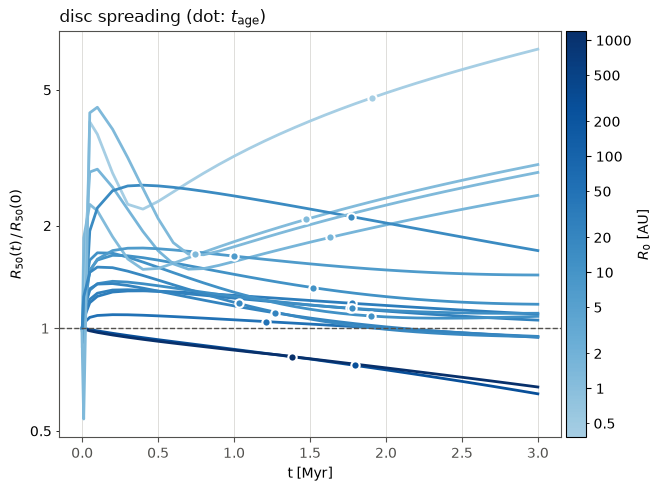

In [ ]:
# =====================================================================================
# 2b. Figure: R50 growth
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"    # text / reference lines / grid
cmap = mcolors.LinearSegmentedColormap.from_list("blues", plt.cm.Blues(np.linspace(0.35, 1.0, 256)))  # one hue, light->dark
norm = mcolors.LogNorm(vmin=comparisons.R0_au.min(), vmax=comparisons.R0_au.max())

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)   # single Axes, not an array
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_color(MUTED)
ax.tick_params(colors=MUTED)

plain = FuncFormatter(lambda v, _: f"{v:g}")         # plain tick numbers on log axes
def tidy_log(ax, which="xy"):
    """Plain tick labels on log axes (call AFTER limits are set): decades always labelled;
    minor ticks at 2 and 5, labelled only when the axis spans < 2 decades."""
    for a, lims in ([(ax.xaxis, ax.get_xlim())] if "x" in which else []) + ([(ax.yaxis, ax.get_ylim())] if "y" in which else []):
        a.set_major_formatter(plain)
        a.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
        a.set_minor_formatter(plain if np.log10(lims[1] / lims[0]) < 2 else NullFormatter())

# R50(t) / R50(0)
for disc_id, (ts, r50s) in r50_tracks.items():
    ts, r50s = np.asarray(ts), np.asarray(r50s)
    c = cmap(norm(draws.loc[disc_id, "R0_au"]))
    ax.plot(ts, r50s / r50s[0], color=c, lw=2)
    row = comparisons.loc[comparisons.id == disc_id].iloc[0]
    if np.isfinite(row.get("R50_growth", np.nan)):
        ax.plot(row.t_age_Myr, row.R50_growth, "o", ms=6, color=c, mec="white", mew=1.5, zorder=3)

ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_yscale("log"); tidy_log(ax, "y")
ax.set_xlabel("t [Myr]"); ax.set_ylabel(r"$R_{50}(t)\,/\,R_{50}(0)$")
ax.set_title(r"disc spreading (dot: $t_{\rm age}$)", loc="left", color=INK)

cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$R_0$ [AU]", pad=0.01)
cb.ax.yaxis.set_major_formatter(plain)
cb.ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
cb.ax.yaxis.set_minor_formatter(plain)
plt.show()

## 3. Malanga et al. (2026) Fig. 4(b): the wind population in the $\dot M$–$M$ plane at the Lupus age
**What Fig. 4(b) shows** (Malanga et al. 2026, Sec. 4.3, p. 9–10): the best-fit MHD-wind synthetic population in the $\dot M$–$M$ plane.
- Each disc is read at its **own** age $t \sim N(\langle t\rangle, \sigma_t)$.
- Colour gives that age on a diverging green→pink scale, centred on the mean age: green = younger, pink = older.
- The black line is the **viscous isochrone** $M/\dot M = 2\,t_{\rm Lupus}$ (their Eq. 9 with $\gamma = 1$, $t \gg t_\nu$).

The paper's point is that the wind population shows **no age gradient** across this line, unlike the viscous one, and has a large spread in $M/\dot M$.

**This cell** builds the same plot for our DiscEvolution hybrid-wind population (cells 1–2):
- **Data:** $M$ = `disk_Mass`/M$_\odot$ and $\dot M$ = `disk_Mdot_star` (M$_\odot$/yr, at $R_c[0] \approx 0.11$ AU), interpolated from the time series (`t` in yr) at each disc's sampled $t_{\rm age}$ (population CSV).
- **Isochrone** uses `LUPUS_MEAN_AGE_MYR` = 1.6 Myr: the mean Lupus age Malanga infer for the wind model (their Table 2 and Sec. 4.3; the $t_{\rm Lupus}$ of their Fig. 4b), **not** the mean of our sampled ages. The literature HR-diagram age they quote is "typically 2 Myr" (Alcalá et al. 2017; Galli et al. 2020), available as an alternative.
- **Colour scale** is centred on the same 1.6 Myr.
- **Survival cut** (`APPLY_DETECTION_CUT`, default on): as in Malanga (Sec. 3, p. 5), discs with $M < 10^{-6}\,M_\odot$ or $\dot M < 10^{-12}\,M_\odot\,{\rm yr}^{-1}$ count as dispersed and are not plotted.
- **No observational scatter** is added; Fig. 4's caption does not mention any, unlike their Figs. 2 and 5.
- **Markers:** GI-flagged discs (cell 1) are **kept**, drawn as triangles instead of circles.
- **`PLOT_WITHOUT_GI = True`** additionally draws the same figure with the GI-flagged discs removed.
- **Axes:** Fig. 4's ranges (log $M$ −6 to −1, log $\dot M$ −12 to −7), widened automatically if any disc falls outside them.

**Differences from Malanga's population to keep in mind:**
- All our discs orbit a $1\,M_\odot$ star, whereas Malanga sample the Lupus stellar-mass function. Our points therefore sit at the high-$M$, high-$\dot M$ end.
- We have $\omega = 0$ (constant $\alpha$), against their $\omega = 0.4$.
- The temperature structure differs (the Step 3 sampler-test flag: initial $\dot M$ ≈ 2.2× the analytic estimate).


500 discs | run does not reach t_age: 0 | below the detection thresholds (dispersed): 35 | plotted: 465 (29 GI-flagged)


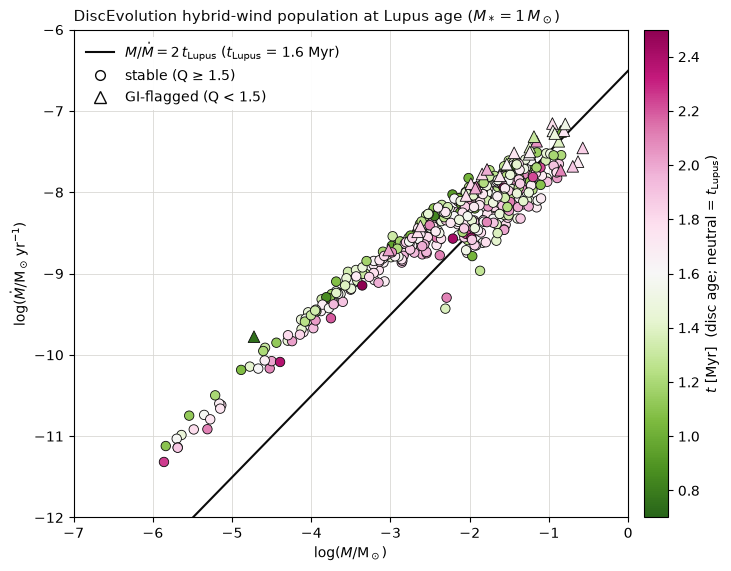

In [6]:
# =====================================================================================
# 3. Malanga et al. (2026) Fig. 4(b): Mdot - M at each disc's age, with the viscous isochrone
#    (needs cell 1: files, draws, run_check, show_table)
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from DiscEvolution.constants import Msun                        # g

# ---- settings ------------------------------------------------------------------------
LUPUS_MEAN_AGE_MYR = 1.6     # Myr: Malanga et al. (2026) inferred mean Lupus age, MHD winds model
                             # (Table 2, Sec. 4.3; t_Lupus of their Fig. 4b). Literature alternative: 2.0
APPLY_DETECTION_CUT = True   # Malanga Sec. 3 (p. 5): discs below these are "dispersed" and not plotted
M_DETECT_MSUN = 1e-6         # Msun
MDOT_DETECT_MSUN_YR = 1e-12  # Msun / yr
PLOT_WITHOUT_GI = False      # True: ALSO draw the same figure with the GI-flagged discs removed
FIG4_XLIM, FIG4_YLIM = (-6, -1), (-12, -7)   # log M [Msun], log Mdot [Msun/yr]: Malanga Fig. 4 axes


def disc_at_age(path, d):
    """(M [Msun], Mdot [Msun/yr]) of one disc at its sampled age t_age (linear interpolation of
    the time series; t in yr). NaN if the run does not reach t_age."""
    with h5py.File(path, "r") as h:
        t = h["t"][:]                                     # yr
        M = h["disk_Mass"][:] / Msun                      # Msun
        Mdot = h["disk_Mdot_star"][:]                     # Msun / yr
    ta = d.t_age_Myr * 1e6                                # yr
    if len(t) < 2 or not (t[0] <= ta <= t[-1]):
        return np.nan, np.nan
    return float(np.interp(ta, t, M)), float(np.interp(ta, t, Mdot))


# ---- the population at the Lupus age --------------------------------------------------
rows = []
for f in files:
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(f)).group(1))
    d = draws.loc[disc_id]
    M_t, Mdot_t = disc_at_age(f, d)
    rows.append({"id": disc_id, "t_age_Myr": d.t_age_Myr, "M_Msun": M_t, "Mdot_Msun_yr": Mdot_t})
fig4 = pd.DataFrame(rows).merge(run_check[["id", "GI_flag"]], on="id", how="left")
fig4["GI_flag"] = fig4.GI_flag.fillna(False).astype(bool)

n_all = len(fig4)
covered = np.isfinite(fig4.M_Msun) & np.isfinite(fig4.Mdot_Msun_yr)
alive = covered & (fig4.M_Msun > 0) & (fig4.Mdot_Msun_yr > 0)       # logs need positive values
if APPLY_DETECTION_CUT:
    alive &= (fig4.M_Msun >= M_DETECT_MSUN) & (fig4.Mdot_Msun_yr >= MDOT_DETECT_MSUN_YR)
plot_df = fig4[alive].copy()
plot_df["logM"], plot_df["logMdot"] = np.log10(plot_df.M_Msun), np.log10(plot_df.Mdot_Msun_yr)
print(f"{n_all} discs | run does not reach t_age: {int((~covered).sum())} | "
      f"{'below the detection thresholds (dispersed)' if APPLY_DETECTION_CUT else 'non-positive M or Mdot'}: "
      f"{int((covered & ~alive).sum())} | plotted: {len(plot_df)} "
      f"({int(plot_df.GI_flag.sum())} GI-flagged)")


def fig4_scales(df):
    """Axis limits and age colour scale shared by every Fig. 4 plot, set from the FULL population
    `df` so the with- and without-GI figures are directly comparable.
    Axes: Fig. 4 ranges, widened (to whole dex) if any disc falls outside.
    Colour: diverging PiYG_r, neutral at the Lupus mean age (green younger, pink older), symmetric
    about it, at least +-0.8 Myr like Fig. 4(b) (0.8-2.4 Myr)."""
    if len(df):
        lims = (min(FIG4_XLIM[0], np.floor(df.logM.min() - 0.2)), max(FIG4_XLIM[1], np.ceil(df.logM.max() + 0.2)),
                min(FIG4_YLIM[0], np.floor(df.logMdot.min() - 0.2)), max(FIG4_YLIM[1], np.ceil(df.logMdot.max() + 0.2)))
        half = max(0.8, float(np.max(np.abs(df.t_age_Myr - LUPUS_MEAN_AGE_MYR))))
    else:
        lims, half = (*FIG4_XLIM, *FIG4_YLIM), 0.8
    norm = mcolors.TwoSlopeNorm(vcenter=LUPUS_MEAN_AGE_MYR,
                                vmin=LUPUS_MEAN_AGE_MYR - half, vmax=LUPUS_MEAN_AGE_MYR + half)
    return lims, norm


def plot_fig4(df, title, lims, norm, color_col="t_age_Myr", cmap=None,
              cbar_label=r"$t$ [Myr]  (disc age; neutral = $t_{\rm Lupus}$)"):
    """Malanga Fig. 4(b)-style plot of `df` (columns logM, logMdot, GI_flag and `color_col`), with the
    shared axis limits `lims` = (xlo, xhi, ylo, yhi) and colour scale `norm` (fig4_scales).
    By default the points are coloured by the disc age (Malanga's Fig. 4b); `color_col` / `cmap` /
    `cbar_label` colour them by another column instead (cell 3b: psi_DW). Everything else is identical."""
    INK, GRID = "#0b0b0b", "#d9d8d4"
    cmap = plt.cm.PiYG_r if cmap is None else cmap
    xlo, xhi, ylo, yhi = lims

    fig, ax = plt.subplots(figsize=(7.2, 5.6), constrained_layout=True)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    # viscous isochrone M / Mdot = 2 t_Lupus  ->  log Mdot = log M - log(2 t_Lupus [yr])
    xs = np.array([xlo, xhi])
    ax.plot(xs, xs - np.log10(2 * LUPUS_MEAN_AGE_MYR * 1e6), color=INK, lw=1.5, zorder=1)
    sc = None
    for marker, sel, size in [("o", ~df.GI_flag, 46), ("^", df.GI_flag, 70)]:
        if sel.any():
            sc = ax.scatter(df.logM[sel], df.logMdot[sel], c=df[color_col][sel], cmap=cmap, norm=norm,
                            marker=marker, s=size, edgecolor=INK, linewidths=0.6, zorder=3)
    ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
    ax.set_xlabel(r"$\log(M/{\rm M_\odot})$"); ax.set_ylabel(r"$\log(\dot M/{\rm M_\odot\,yr^{-1}})$")
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    handles = [Line2D([], [], color=INK, lw=1.5,
                      label=rf"$M/\dot M = 2\,t_{{\rm Lupus}}$ ($t_{{\rm Lupus}}$ = {LUPUS_MEAN_AGE_MYR:g} Myr)"),
               Line2D([], [], marker="o", ls="", mfc="white", mec=INK, ms=7, label="stable (Q ≥ 1.5)")]
    if df.GI_flag.any():
        handles.append(Line2D([], [], marker="^", ls="", mfc="white", mec=INK, ms=8, label="GI-flagged (Q < 1.5)"))
    ax.legend(handles=handles, loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.95)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
    cb.set_label(cbar_label)
    plt.show()


fig4_lims, fig4_norm = fig4_scales(plot_df)          # shared by both figures below
plot_fig4(plot_df, "DiscEvolution hybrid-wind population at Lupus age ($M_* = 1\\,M_\\odot$)", fig4_lims, fig4_norm)
if PLOT_WITHOUT_GI:
    no_gi = plot_df[~plot_df.GI_flag]
    print(f"Without GI-flagged discs: {len(no_gi)} plotted ({int(plot_df.GI_flag.sum())} removed)")
    plot_fig4(no_gi, "Same, GI-flagged discs removed (same axes and colour scale)", fig4_lims, fig4_norm)


In [ ]:
# =====================================================================================
# 3b. Same Fig. 4(b) plot, coloured by psi_DW instead of disc age (needs cell 3)
# =====================================================================================
# IDENTICAL to cell 3 -- same discs (plot_df: same survival cut), same axes (fig4_lims), same
# isochrone M/Mdot = 2 t_Lupus, same markers (triangles = GI-flagged) -- except the colour, which is
# the disc's wind parameter psi_DW = alpha_tot / alpha_SS - 1 [dimensionless] (population CSV).
# Why psi: with alpha_SS fixed at 1e-4, psi sets the TOTAL alpha (alpha_tot = alpha_SS (1 + psi)) and
# hence the accretion timescale, so if the position relative to the isochrone tracks psi, the
# M/Mdot spread is driven by the sampled alpha_DW rather than by age.
# Colour scale: sequential (one hue, light = low psi -> dark = high psi), linear over the psi range of
# the plotted discs. PLOT_WITHOUT_GI (cell 3) also applies here.
from matplotlib import colors as mcolors
import inspect

# Stale-kernel check: this cell needs cell 3's CURRENT plot_fig4 (with the color_col argument). If the
# kernel still holds an older definition (cell 3 not re-run since the notebook was updated), stop with
# a clear message instead of a TypeError.
if "color_col" not in inspect.signature(plot_fig4).parameters:
    raise RuntimeError("plot_fig4 in this kernel is an OLD version: reload the notebook from disk "
                       "(VS Code: close/reopen or 'Revert File'), then re-run cell 3 before this cell.")

psi_df = plot_df.merge(draws[["psi_DW"]], left_on="id", right_index=True, how="left")
psi_cmap = mcolors.LinearSegmentedColormap.from_list("psi", plt.cm.Purples(np.linspace(0.25, 1.0, 256)))
psi_norm = (mcolors.Normalize(vmin=psi_df.psi_DW.min(), vmax=psi_df.psi_DW.max()) if len(psi_df)
            else mcolors.Normalize(vmin=0, vmax=1))
print(f"psi_DW of the {len(psi_df)} plotted discs: min {psi_df.psi_DW.min():.3g}, "
      f"median {psi_df.psi_DW.median():.3g}, max {psi_df.psi_DW.max():.3g}")
psi_label = r"$\psi_{\rm DW} = \alpha_{\rm tot}/\alpha_{\rm SS} - 1$"

plot_fig4(psi_df, "DiscEvolution hybrid-wind population at Lupus age, coloured by $\\psi$",
          fig4_lims, psi_norm, color_col="psi_DW", cmap=psi_cmap, cbar_label=psi_label)
if PLOT_WITHOUT_GI:
    plot_fig4(psi_df[~psi_df.GI_flag], "Same, GI-flagged discs removed (same axes and colour scale)",
              fig4_lims, psi_norm, color_col="psi_DW", cmap=psi_cmap, cbar_label=psi_label)
